# Simulation

In [1]:
import os

from __future__ import annotations

from dataclasses import dataclass
from typing import List

import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset

from copy import deepcopy

import random

from pathlib import Path

SEED = 69
np.random.seed(SEED)
torch.manual_seed(SEED)

Array = np.ndarray


@dataclass
class SimulationConfig:
    nx = 16
    ny = 16
    pixel_size_m = 2e-6
    z_length_m = 3e-6
    z_speed_um_s = 9.0
    sampling_frequency_hz = 9000
    setpoint_force_n = 1.0e-9
    tip_shape = "Sphere"
    include_thermal_noise = True
    noise_type = "experimental"
    experimental_noise_path = \
      "thermal-noise-data_vDeflection_2025.11.28-16.42.57.tnd"
    curve_mode = "approach_retract"  # options: "approach", "approach_retract"

@dataclass
class DatasetConfig:
    n_train_samples = 20
    n_val_samples = 15
    n_test_samples = 10
    topography_types = ("gaussian_features", "hemisphere")
    substrate_stiffness_range_pa = (1e3, 5e3)
    feature_stiffness_range_pa = (0.1e3, 5e3)
    height_range_m = (0.1e-6, 1.5e-6)
    contact_point_range_m = (0.01e-6, 2.9e-6)

@dataclass
class ModelConfig:
    batch_size = 256
    learning_rate = 2e-3
    max_epochs =10
    predict_contact_point = True
    cp_loss_weight = 0.5
    num_workers = 0
    accelerator = "auto"
    devices = 1
    default_sample_to_display = 0


simulation_config = SimulationConfig()
dataset_config = DatasetConfig()
model_config = ModelConfig()

print(simulation_config)
print(dataset_config)
print(model_config)

class HertzContact:
    """Hertz contact model for spherical and pyramidal tips.

    Represents the relationship between indentation and force. Stores
    information related to contact geometry and contact mechanics.

    Parameters
    ----------
    R: float
        Tip radius in meters.
    nu: float
        Poisson ratio of the sample.
    alpha: float
        Pyramid face angle in degrees.

    """

    def __init__(
        self,
        R: float = 10e-9,
        nu: float = 0.5,
        alpha: float = 18.0
    ) -> None:
        """Initializes the HertzContact model.

        Initializes the HertzContact model with given parameters.

        Parameters
        ----------
        R: float
            Tip radius in meters.
        nu: float
            Poisson ratio of the sample.
        alpha: float
            Pyramid face angle in degrees.

        """

        self.R = R
        self.nu = nu
        self.alpha = alpha

    @property
    def alpha_rad(
        self
    ) -> float:
        """Return the pyramid face angle in radians.

        Returns
        -------
        float
            Pyramid face angle in radians.

        """

        return np.deg2rad(self.alpha)

    def hertz_sphere(
        self,
        indentation_m: float,
        stiffness_pa: float
    ) -> float:
        """Return the Hertz force for a spherical tip.

        Returns the force response of a purely elastic semi finite substrate
        with the given stiffness in response to given indentation depth for a
        spherical indentor.

        Parameters
        ----------
        indentation_m : float
            Indentation depth in meters.
        stiffness_pa : float
            Young's modulus in pascal.

        Returns
        -------
        float
            Contact force in newtons.

        """

        return (
            (4.0 / 3.0)
            * stiffness_pa
            * np.sqrt(self.R)
            * indentation_m**1.5
            / (1.0 - self.nu**2)
        )

    def hertz_cone(
        self,
        indentation_m: float,
        stiffness_pa: float
    ) -> float:
        """Return the Hertz-like force for a conical approximation.

        Returns the force response of a purely elastic semi finite substrate
        with the given stiffness in response to given indentation depth for a
        conical indentor.

        Parameters
        ----------
        indentation_m : float
            Indentation depth in meters.
        stiffness_pa : float
            Young's modulus in pascal.

        Returns
        -------
        float
            Contact force in newtons.

        """

        return (
            stiffness_pa
            * np.tan(self.alpha_rad)
            * indentation_m**2
            / (np.sqrt(2.0) * (1.0 - self.nu**2))
        )

    def force(
        self: HertzContact,
        cantilever_shape: str,
        indentation_m: float,
        stiffness_pa: float,
        stiffness_2_pa: float = None,
        transition_depth_m: float = None,
    ) -> float:
        """Return the contact force for the given indentation.

        Supports an optional two-stiffness (bi-layer) mode.  When both
        ``stiffness_2_pa`` and ``transition_depth_m`` are provided, the model
        uses ``stiffness_pa`` (E1) for the surface layer and
        ``stiffness_2_pa`` (E2) for any additional indentation beyond
        ``transition_depth_m``.  The force is continuous at the transition:

            F(δ) = Hertz(min(δ, δ_t), E1) + Hertz(max(0, δ − δ_t), E2)

        Parameters
        ----------
        cantilever_shape: str
            Tip geometry, either ``'Sphere'`` or ``'Pyramid'``.
        indentation_m: float
            Indentation depth in meters.
        stiffness_pa: float
            Young's modulus of the first (surface) layer in pascal.
        stiffness_2_pa: float or None, optional
            Young's modulus of the second (stiffer) layer in pascal.
            Bi-layer mode is activated only when both this and
            ``transition_depth_m`` are not None.
        transition_depth_m: float or None, optional
            Indentation depth at which the tip reaches the second layer [m].

        Returns
        -------
        float
            Contact force in newtons.

        """

        indent = np.maximum(np.asarray(indentation_m, dtype=np.float64), 0.0)

        if stiffness_2_pa is not None and transition_depth_m is not None:
            t  = np.asarray(transition_depth_m, dtype=np.float64)
            E2 = np.asarray(stiffness_2_pa,     dtype=np.float64)
            below = np.minimum(indent, t)        # indentation absorbed by layer 1
            extra = np.maximum(indent - t, 0.0) # extra indentation into layer 2
            if cantilever_shape == "Sphere":
                return self.hertz_sphere(below, stiffness_pa) +\
                 self.hertz_sphere(extra, E2)
            if cantilever_shape == "Pyramid":
                return self.hertz_cone(below, stiffness_pa) +\
                 self.hertz_cone(extra, E2)
            raise ValueError(f"Unsupported cantilever shape: \
            {cantilever_shape}")

        if cantilever_shape == "Sphere":
            return self.hertz_sphere(indent, stiffness_pa)
        if cantilever_shape == "Pyramid":
            return self.hertz_cone(indent, stiffness_pa)
        raise ValueError(f"Unsupported cantilever shape: {cantilever_shape}")

class AFMCantilever:
    """AFM cantilever model with thermal-noise PSD support.

    This class represents the cantilever and stores parameters relevant to its
    thermal noise characteristics, allowing for both theoretical and
    experimental PSDs to be used in simulations.

    Parameters
    ----------
    k : float
        Spring constant in N/m.
    f0 : float
        Resonance frequency in Hz.
    Q : float
        Quality factor.
    T : float
        Temperature in kelvin.

    """

    def __init__(
        self,
        k: float =0.1,
        f0: float =7e3,
        Q: float =10.0,
        T: float =300.0
    ) -> None:
        """Initializes the AFMCantilever.

        Initializes the AFMCantilever with given parameters and computes
        derived properties.

        Parameters
        ----------
        k : float, optional
            Spring constant in N/m (default is 0.1).
        f0 : float, optional
            Resonance frequency in Hz (default is 7e3).
        Q : float, optional
            Quality factor (default is 10.0).
        T : float, optional
            Temperature in kelvin (default is 300.0).

        """

        self.k = k
        self.f0 = f0
        self.Q = Q
        self.T = T
        self.kB = 1.380649e-23
        self.m_eff = k / (2.0 * np.pi * f0) ** 2
        self.gamma = 2.0 * np.pi * f0 * self.m_eff / Q
        self._experimental_psd_cache = {}
        self._grid_psd_cache = {}

    def thermal_noise_rms(
            self
        ) -> float:
        """Return the RMS thermal deflection in meters.

        Returns
        -------
        float
            RMS thermal deflection in meters.

        """

        return np.sqrt(self.kB * self.T / self.k)

    def thermal_noise_psd_theoretical(
        self,
        frequency_hz: np.ndarray
    ) -> np.ndarray:
        """Return the one-sided theoretical displacement PSD.

        Parameters
        ----------
        frequency_hz : np.ndarray
                Frequencies in Hz at which to evaluate the PSD.

        Returns
        -------
        np.ndarray
            PSD in m^2/Hz.

        """

        omega  = 2.0 * np.pi * frequency_hz
        omega0 = 2.0 * np.pi * self.f0
        denom  = (omega0**2 - omega**2)**2 + (omega * omega0 / self.Q)**2
        return (4.0 * self.kB * self.T * self.gamma) / (self.k**2 * denom)

    def thermal_noise_psd_experimental(
        self,
        path: str
    ) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
        """Load and cache an experimental displacement PSD.

        Loads the experimental PSD from the provided path. Converts the
        displacement from volts to meters using the metadata in the file.

        Parameters
        ----------
        path : str
            Path to the experimental PSD file.

        Returns
        -------
        tuple of np.ndarray
            (frequency_hz, spectral_density_x, spectral_density_x_fit)

        """

        cache_key = str(path)
        if cache_key not in self._experimental_psd_cache:
            data = np.loadtxt(path, skiprows=24)
            frequency_hz       = data[:, 0]
            spectral_density_v = data[:, 1]
            spectral_density_v_fit = data[:, 3]
            with open(path, "r") as f:
                lines = f.readlines()
            for line in lines:
                if "sensitivity" in line:
                    volts_to_displacement_nm = \
                      float(line.split(":")[1].split()[0])
                if "parameter.f" in line:
                    self.f0 = float(line.split(":")[1].split()[0]) * 1e3
                if "parameter.Q" in line:
                    self.Q = float(line.split(":")[1].split()[0])
            scale = volts_to_displacement_nm * 1e-9
            self._experimental_psd_cache[cache_key] = (
                frequency_hz,
                spectral_density_v     * scale**2,
                spectral_density_v_fit * scale**2,
            )
        return self._experimental_psd_cache[cache_key]

    def get_noise_psd(
        self,
        n_points: int,
        sampling_frequency_hz: float,
        noise_type: str = simulation_config.noise_type,
        experimental_path: str = simulation_config.experimental_noise_path
    ) -> tuple[np.ndarray, np.ndarray]:
        """Returns the simulation-grid PSD.

        Returns the theoretical PSD calculated with the harmonic oscillator
        model. When it's possible the cached results are reused.

        Parameters
        ----------
        n_points : int
            Number of points in the simulation grid.
        sampling_frequency_hz : float
            Sampling frequency in Hz.
        noise_type : str
            Type of noise ("theoretical", "experimental" or "rms").
        experimental_path : str or None
            Path to the experimental PSD file.

        Returns
        -------
        tuple of np.ndarray
            (frequency_hz, spectral_density_x)

        """

        cache_key = (noise_type.lower(), int(n_points), \
                     float(sampling_frequency_hz),None if experimental_path
                     is None else str(experimental_path))
        if cache_key in self._grid_psd_cache:
            return self._grid_psd_cache[cache_key]

        frequency_hz = np.fft.rfftfreq(n_points, d=1.0 / sampling_frequency_hz)
        if noise_type.lower() == "theoretical":
            spectral_density_x = \
              self.thermal_noise_psd_theoretical(frequency_hz)
        elif noise_type.lower() == "experimental":
            if experimental_path is None:
                raise ValueError("`experimental_path` must be provided for \
                experimental PSD.")
            frequency_hz, spectral_density_x, _ = (
                self.thermal_noise_psd_experimental(experimental_path)
            )
        else:
            raise ValueError(f"Unknown noise type: {noise_type}")

        self._grid_psd_cache[cache_key] = (frequency_hz, spectral_density_x)
        return self._grid_psd_cache[cache_key]

    def sample_thermal_noise(
        self,
        n_points: int,
        sampling_frequency_hz: float,
        noise_type: str = simulation_config.noise_type,
        experimental_path: str = simulation_config.experimental_noise_path,
        rng=None
    ) -> np.ndarray:
        """Draws one thermal-noise trace from the PSD.

        Draws one trace of thermal noise from the PSD using random phase and
        converts it to time domain noise using np.fft.irfft

        Parameters
        ----------
        n_points : int
            Number of points in the simulation grid.
        sampling_frequency_hz : float
            Sampling frequency in Hz.
        noise_type : str
            Type of noise ("theoretical", "experimental" or "rms").
        experimental_path : str or None
            Path to the experimental PSD file.
        rng : numpy.random.Generator or None
            Random number generator instance. If None, a new instance is
            created.

        Returns
        -------
        np.ndarray
            Noise trace in meters, shape (n_points,).

        """

        rng = np.random.default_rng() if rng is None else rng
        frequency_hz, spectral_density_x = self.get_noise_psd(
            n_points, sampling_frequency_hz, noise_type, experimental_path
        )
        df        = sampling_frequency_hz / n_points

        amplitude = n_points * \
                            np.sqrt(np.maximum(spectral_density_x * df/2, 0.0))
        coefficients = np.zeros(amplitude.shape[0], dtype=np.complex128)

        if amplitude.shape[0] > 2:
            phase = rng.uniform(0.0, 2.0 * np.pi, size=amplitude.shape[0] - 2)
            coefficients[1:-1] = amplitude[1:-1] * np.exp(1j * phase)
        coefficients[0] = 0.0
        if n_points % 2 == 0 and amplitude.shape[0] > 1:
            coefficients[-1] = amplitude[-1] * np.sign(rng.standard_normal())

        noise_m = np.fft.irfft(coefficients, n=n_points).real
        rms      = self.thermal_noise_rms()
        std      = np.std(noise_m)
        # Guard against zero std.
        if std > 0:
            noise_m = noise_m / std * rms
        else:
            noise_m = rng.normal(scale=rms, size=n_points)
        return noise_m

cantilever = AFMCantilever(k=0.178, f0=10e3, Q=100.0, T=300.0)
contact_model = HertzContact(R=1e-6, nu=0.5, alpha=18.0)

cantilever=cantilever
contact_model=contact_model
config=simulation_config

def _compute_n_points_approach(
) -> int:
    """ Compute the number of points for the approach phase

    Computes the number of points for the approach phasebased on the z-length,
    z-speed, and sampling frequency.

    Returns
    -------
    int
        Number of points for the approach phase, at least 32.

    """

    total_time_s = config.z_length_m / \
      (config.z_speed_um_s * 1e-6)
    return max(32, int(np.ceil(total_time_s * \
                                config.sampling_frequency_hz)))

def _build_approach_axis(
) -> np.ndarray:
    """Build the approach displacement axis.

    Builds the approach displacement axis as a linearly spaced array from 0 to z_length_m with n_points_approach points.

    Returns
    -------
    np.ndarray
        Approach displacement axis in meters, shape (n_points_approach,).

    """

    return np.linspace(0.0, config.z_length_m, \
                       n_points_approach, \
                        endpoint=True, dtype=np.float64)

def _retract_axis(
    z_start_m: float
) -> np.ndarray:
    """Return the retract displacement axis

    Returns the retract displacement axis starting from ``z_start_m``.

    Parameters
    ----------
    z_start_m : float
        Starting z-position for the retract phase in meters.

    Returns
    -------
    np.ndarray
        Retract displacement axis in meters.

    """

    z_stop_m = max(0.0, z_start_m - config.z_length_m)
    if z_stop_m >= z_start_m:
        return np.zeros(0, dtype=np.float64)
    n = max(1, int(np.ceil(
        (z_start_m - z_stop_m) / (config.z_speed_um_s * 1e-6) \
        * config.sampling_frequency_hz
    )))
    return np.linspace(z_start_m, z_stop_m, n + 1, \
                       endpoint=True)[1:].astype(np.float64)

SimulationConfig()
DatasetConfig()
ModelConfig()


In [2]:
stiffness_range_pa = (0.1e3, 5e3)
contact_point_range_m = (0.01e-6, 2.9e-6)
align_length = 1500
rng = np.random.default_rng()

z_length_m = simulation_config.z_length_m

data_x = []
data_y = []

for i in range(10000):

    n_points_approach = _compute_n_points_approach()
    approach_axis_m   = _build_approach_axis()

    stiffness_pa = rng.uniform(stiffness_range_pa[0], stiffness_range_pa[1])
    contact_point_m = rng.uniform(contact_point_range_m[0], contact_point_range_m[1])
    
    approach_indent = np.maximum(
    approach_axis_m - contact_point_m, 0.0
    )

    stiffness_2_pa = stiffness_pa / rng.uniform(
        1, 20
    )

    max_indent_m = np.maximum(
                z_length_m - contact_point_m, 0.0
            )

    fraction = rng.uniform(0.1, 0.3)
    transition_depth = max_indent_m*fraction

    if random.random() < 1/3:
        
        approach_force = contact_model.force(
            cantilever_shape=config.tip_shape,
            indentation_m=approach_indent,
            stiffness_pa=stiffness_2_pa,
            stiffness_2_pa =stiffness_pa,
            transition_depth_m  = transition_depth,
        )

    else:

        approach_force = contact_model.force(
            cantilever_shape=config.tip_shape,
            indentation_m=approach_indent,
            stiffness_pa=stiffness_pa,
        )
        
    exceeded = approach_force >= config.setpoint_force_n
    
    cp    = float(contact_point_m)
    E     = float(stiffness_pa)


    contact_indices = np.clip(
        np.searchsorted(approach_axis_m, contact_point_m,
                        side="left"),
        0, n_points_approach - 1,
    )

    # ── approach ─────────────────────────────────────────────────
    if True in exceeded:
        ei = first_exceed   = np.argmax(exceeded)
    
        app_z = approach_axis_m[:ei]
        app_f = approach_force[:ei]
        
    else:

        app_z = approach_axis_m.copy()
        app_f = approach_force.copy()
    
    # ── retract ──────────────────────────────────────────────────
    ret_z = _retract_axis(float(app_z[-1]))

    ret_f = contact_model.force(
        config.tip_shape,
        np.maximum(ret_z - cp, 0.0),
        E,
    )

    cp_idx = int(contact_indices)
    tip_app_ind = app_z[cp_idx:] - \
    app_f[cp_idx:] / cantilever.k
    tip_app = np.concatenate([app_z[:cp_idx], tip_app_ind])
    tip_ret_ind = ret_z[cp_idx:] - \
    ret_f[cp_idx:] / cantilever.k
    tip_ret = np.concatenate([ret_z[:cp_idx], tip_ret_ind])

    disp_z  = np.concatenate([app_z, ret_z])
    disp_tip  = np.concatenate([tip_app, tip_ret])
    force_n = np.concatenate([app_f, ret_f])
    retract_start = app_z.size
    
    # ── thermal noise ────────────────────────────────────────────
    noise_m = np.zeros_like(force_n)
    if True:
        if simulation_config.noise_type == "rms":
            sigma = cantilever.thermal_noise_rms()
            noise_m += np.random.normal(-sigma, sigma,
                                        size=len(noise_m))
        else:
            noise_m = cantilever.sample_thermal_noise(
                n_points=disp_z.size,
                sampling_frequency_hz= \
                  config.sampling_frequency_hz,
                noise_type=simulation_config.noise_type,
                experimental_path=simulation_config.experimental_noise_path,
                rng=rng,
            )

    displacement_curves_m   = disp_z
    displacement_tip_curves_m   = disp_tip
    force_curves_n         = force_n
    if random.random() < 0.95:
        measured_force_curves_n = force_n + noise_m * cantilever.k * random.random()
    else:
        measured_force_curves_n = force_n
        
    #measured_force_curves_n = force_n
    curve_lengths           = disp_z.size
    retract_start_indices   = retract_start

    #plt.plot(measured_force_curves_n[:tip_app.shape[0]])
    #plt.show()
    #print(fraction)
    #print(stiffness_2_pa)
    #print(stiffness_pa)

    
    cp = deepcopy(contact_point_m)
    stif = deepcopy(stiffness_pa)
    
    disp = tip_app.copy()
    meas = measured_force_curves_n[:tip_app.shape[0]].copy()

    cp = disp.max() - cp
    disp = disp.max() - disp
    cp = cp/disp.max()

    cut1 = int(random.random()*0.5*cp*disp.size)
    cut2 = int((1-(1-cp)*random.random()*0.9)*disp.size)

    cp = cp*disp.max()

    disp = disp[::-1]
    meas = meas[::-1]


    x_old = np.linspace(0, 1, disp.size)
    x_new = np.linspace(0, 1, align_length)

    disp = np.interp(x_new, x_old, disp)
    meas = np.interp(x_new, x_old, meas)


    cp = cp - disp.min()
    disp = disp - disp.min()
    cp = cp/disp.max()

    disp = disp[::-1]
    meas = meas[::-1]
    meas_ = deepcopy(meas)


    cp = deepcopy(contact_point_m)
    stif = deepcopy(stiffness_pa)
    
    disp = tip_app.copy()
    meas = force_curves_n[:tip_app.shape[0]].copy()

    cp = disp.max() - cp
    disp = disp.max() - disp
    cp = cp/disp.max()

    cut1 = int(random.random()*0.5*cp*disp.size)
    cut2 = int((1-(1-cp)*random.random()*0.9)*disp.size)

    cp = cp*disp.max()

    disp = disp[::-1]
    meas = meas[::-1]


    x_old = np.linspace(0, 1, disp.size)
    x_new = np.linspace(0, 1, align_length)

    disp = np.interp(x_new, x_old, disp)
    meas = np.interp(x_new, x_old, meas)


    cp = cp - disp.min()
    disp = disp - disp.min()
    cp = cp/disp.max()

    disp = disp[::-1]
    meas = meas[::-1]


    
    data_x.append(np.hstack([meas_*1e9,meas*1e9]))
    data_y.append([cp, stif])

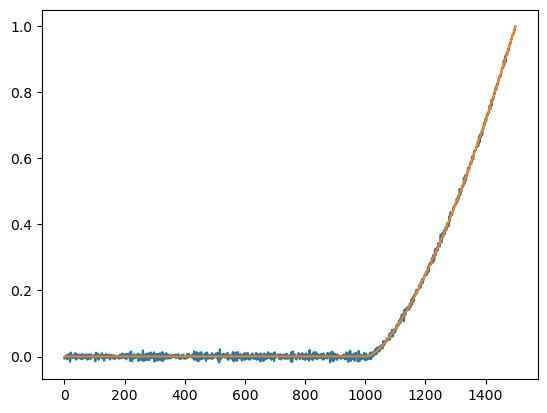

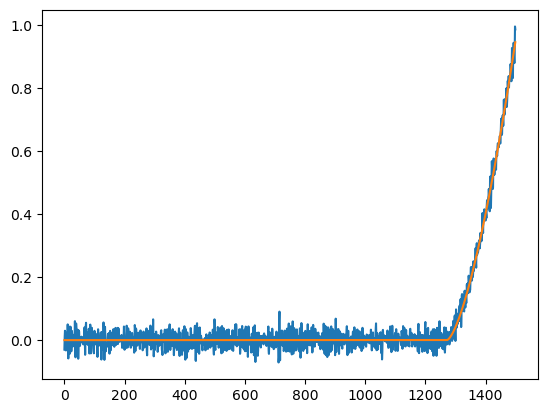

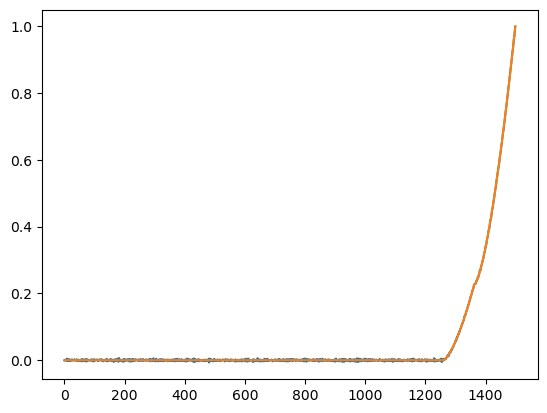

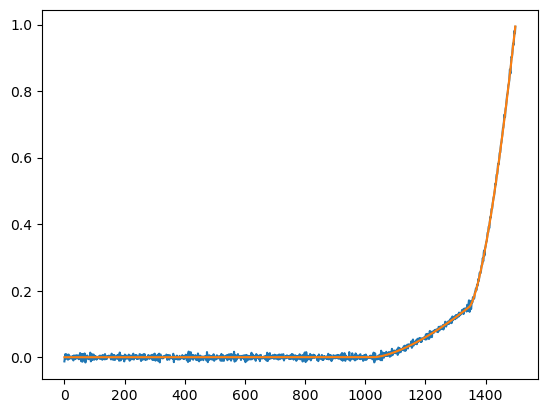

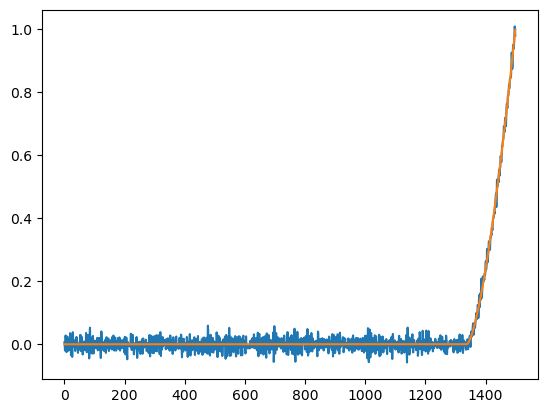

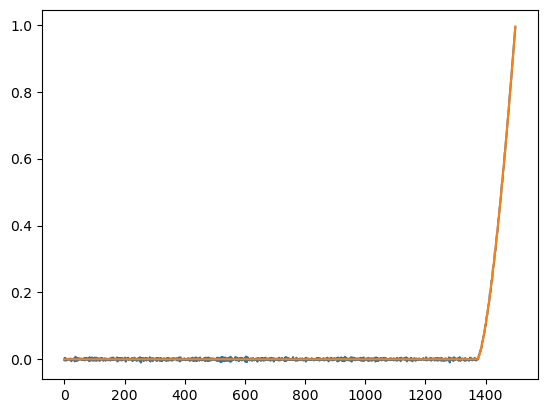

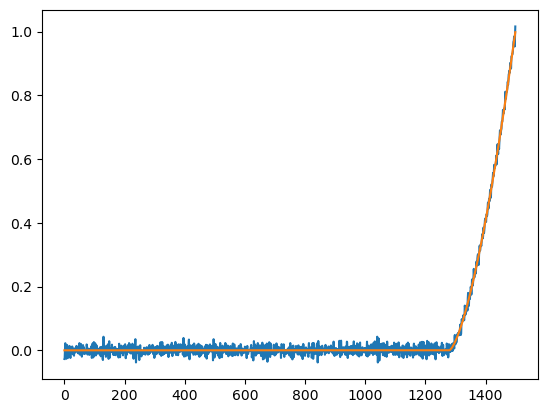

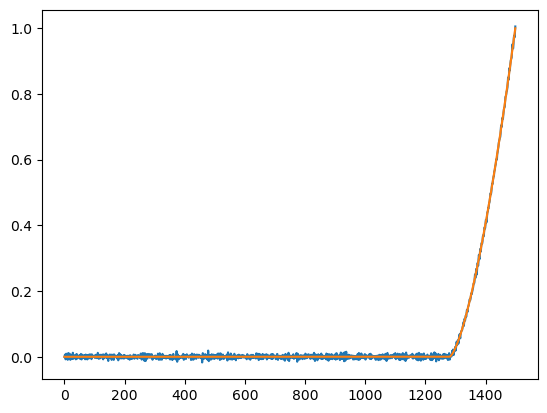

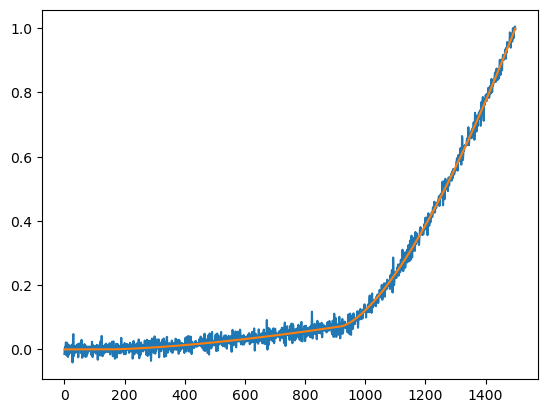

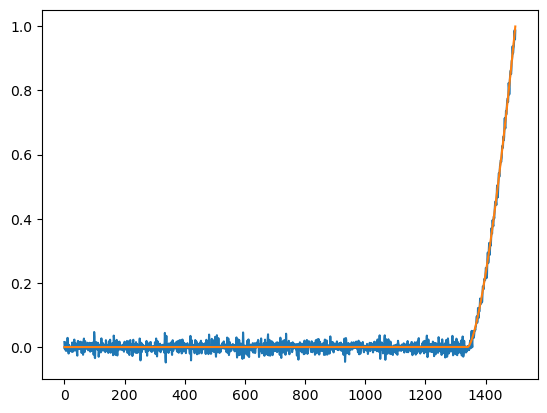

In [3]:
for i in range(10):
    plt.plot(data_x[i][:1500])
    plt.plot(data_x[i][1500:])
    plt.show()

In [4]:
norm_approach_curves = []

for curve in data_x:
    resampled_approach_curve = curve
    norm_approach_curves.append(
        (resampled_approach_curve - resampled_approach_curve.min())
        / (resampled_approach_curve.max() - resampled_approach_curve.min())
    )


# MLP Filter

In [5]:
import torch
from torch.utils.data import TensorDataset, random_split
import deeplay as dl
from sklearn.model_selection import train_test_split


In [6]:
good_norm_approach_curves = norm_approach_curves

(
    curves_train,
    curves_test,
) = train_test_split(
    good_norm_approach_curves,
    test_size=0.2,
    random_state=577,
)

curves_train = np.array(curves_train)
curves_test = np.array(curves_test)

In [7]:
len(curves_train)

8000

In [8]:
len(curves_test)

2000

In [9]:
# Transfer them to Torch.Tensor

train_x = torch.as_tensor(curves_train[:,0:1500], dtype=torch.float32)
train_y = torch.as_tensor(curves_train[:,1500:3000], dtype=torch.float32)


test_x = torch.as_tensor(curves_test[:,0:1500], dtype=torch.float32)
test_y = torch.as_tensor(curves_test[:,1500:3000], dtype=torch.float32)


# Instantiate the dataloader for train data
train_dataloader = dl.DataLoader(
    TensorDataset(train_x, train_x),
    batch_size=40960, shuffle=True
)

# Instantiate the dataloader for test data
test_dataloader = dl.DataLoader(
    TensorDataset(test_x, test_x),
    batch_size=40960, shuffle=True
)

In [10]:
from ae import AutoEncoder

min_approach_curve_length = 1500

# Instantiate the cAE model according to the data properties
ae = AutoEncoder(
    input_size=min_approach_curve_length,
    channels=[512, 256, 128, 64],
    reconstruction_loss=torch.nn.MSELoss(reduction="mean"),
    latent_dim=2,
)

# Configure the activated function
ae.encoder.blocks[:].activated(torch.nn.Tanh)
ae.decoder.blocks[:4].activated(torch.nn.Tanh)
ae.decoder.blocks[4].activated(torch.nn.Sigmoid)

# Create the AE application
ae = ae.create()

print(ae)

AutoEncoder(
  (encoder): MultiLayerPerceptron(
    (blocks): LayerList(
      (0): LinearBlock(
        (layer): Linear(in_features=1500, out_features=512, bias=True)
        (activation): Tanh()
      )
      (1): LinearBlock(
        (layer): Linear(in_features=512, out_features=256, bias=True)
        (activation): Tanh()
      )
      (2): LinearBlock(
        (layer): Linear(in_features=256, out_features=128, bias=True)
        (activation): Tanh()
      )
      (3): LinearBlock(
        (layer): Linear(in_features=128, out_features=64, bias=True)
        (activation): Tanh()
      )
      (4): LinearBlock(
        (layer): Linear(in_features=64, out_features=64, bias=True)
        (activation): Tanh()
      )
    )
  )
  (fc_enc): Linear(in_features=64, out_features=2, bias=True)
  (fc_dec): Linear(in_features=2, out_features=64, bias=True)
  (decoder): MultiLayerPerceptron(
    (blocks): LayerList(
      (0): LinearBlock(
        (layer): Linear(in_features=64, out_features=64,

In [11]:
from lightning.pytorch.callbacks import ModelCheckpoint
from pytorch_lightning.loggers import CSVLogger

# Save the top-1 model according to the validation loss
checkpoint_callback = ModelCheckpoint(
    monitor="val_total_loss",
    mode="min",
    save_top_k=1,
)

# Set the logger
csv_logger = CSVLogger("logs")

# Instantiate the trainer
ae_trainer = dl.Trainer(
    max_epochs=5_000,
    accelerator="auto",
    callbacks=[checkpoint_callback],
    logger=csv_logger,
    enable_progress_bar=False,
)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


In [12]:
ae_trainer.fit(ae, train_dataloader, test_dataloader)

You are using a CUDA device ('NVIDIA A100-PCIE-40GB') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision


┏━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name                ┃ Type                 ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ encoder             │ MultiLayerPerceptron │  945 K │ train │     0 │
│ 1 │ fc_enc              │ Linear               │    130 │ train │     0 │
│ 2 │ fc_dec              │ Linear               │    192 │ train │     0 │
│ 3 │ decoder             │ MultiLayerPerceptron │  946 K │ train │     0 │
│ 4 │ reconstruction_loss │ MSELoss              │      0 │ train │     0 │
│ 5 │ train_metrics       │ MetricCollection     │      0 │ train │     0 │
│ 6 │ val_metrics         │ MetricCollection     │      0 │ train │     0 │
│ 7 │ test_metrics        │ MetricCollection     │      0 │ train │     0 │
│ 8 │ optimizer           │ Adam                 │      0 │ train │     0 │
└───┴─────────────────────┴──────────────────────┴────────┴───────┴───────┘

Trainable params: 1.9 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 1.9 M                                                                                                
Total estimated model params size (MB): 7.568                                                                      
Modules in train mode: 41                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

/opt/conda/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/opt/conda/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:485: Your `val_dataloader`'s sampler has shuffling enabled, it is strongly recommended that you turn shuffling off for val/test dataloaders.
/opt/conda/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=63` in the `DataLoader` to improve performance.
/opt/conda/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=63` in the

In [13]:
print(f"The best model is saved at {checkpoint_callback.best_model_path}")

best_ae = AutoEncoder.load_from_checkpoint(
    checkpoint_callback.best_model_path
)

The best model is saved at logs/lightning_logs/version_25/checkpoints/epoch=4996-step=4997.ckpt


In [14]:
# Evaluate performance of trained AE on train dataset

_ = ae_trainer.test(best_ae, train_dataloader)

/opt/conda/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:485: Your `test_dataloader`'s sampler has shuffling enabled, it is strongly recommended that you turn shuffling off for val/test dataloaders.
/opt/conda/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=63` in the `DataLoader` to improve performance.


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│   test_total_loss_epoch   │   0.0006196909234859049   │
└───────────────────────────┴───────────────────────────┘

In [15]:
# Evaluate performance of trained AE on test dataset

_ = ae_trainer.test(best_ae, test_dataloader)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│   test_total_loss_epoch   │   0.0006022558663971722   │
└───────────────────────────┴───────────────────────────┘

# 3T3

In [16]:
from pathlib import Path
import numpy as np
import shutil

# Load the approach curves
approach_path = Path.cwd() / "3t3_cell_dataset" / "approach"
approach_files = sorted(approach_path.glob("*.npy"), key=lambda f: int(f.stem))
approach_curves = [np.load(f) for f in approach_files]

# Load the retraction curves
retract_path = Path.cwd() / "3t3_cell_dataset" / "retraction"
retract_files = sorted(retract_path.glob("*.npy"), key=lambda f: int(f.stem))
retract_curves = [np.load(f) for f in retract_files]

# Load the labels
labels = np.load(Path.cwd() / "3t3_cell_dataset" / "label.npy")

# Load the contact points
contactpoints = np.load(Path.cwd() / "3t3_cell_dataset" / "contact_point.npy")




def label_separate(labels: np.ndarray[int], 
                   label: int, 
                   *arrays: np.ndarray,
) -> tuple[list, ...]:
    """Separates data based on a specified label.

    This utility function filters multiple aligned NumPy arrays according
    to a given label. It returns subsets of the input arrays where the
    labels match the specified value.

    Parameters
    ----------
    labels : np.ndarray[int]
        Array of labels used for filtering.
    label : int
        Target label to select.
    *arrays : np.ndarray
        One or more NumPy arrays aligned with `labels`. All arrays must
        have the same length as `labels`.

    Returns
    -------
    tuple[list, ...]
        A tuple where each element corresponds to a filtered version of
        the input arrays, containing only elements whose label matches
        the specified value.

    Examples
    --------
    >>> labels = np.array([0, 0, 1, 1, 1])
    >>> label = 1
    >>> list1 = np.array([1, 2, 3, 4, 5])
    >>> list2 = np.array([5, 4, 3, 2, 1])
    >>> s_l1, s_l2 = label_separate(labels, label, list1, list2)
    >>> s_l1, s_l2
    ([3, 4, 5], [3, 2, 1])

    """

    idx = np.where(labels == label)[0]
    return tuple([[arr[i] for i in idx] for arr in arrays])



# Calculate the length of each curve
approach_curve_lengths = [curve.shape[0] for curve in approach_curves]
retract_curve_lengths = [curve.shape[0] for curve in retract_curves]

# Calculate the minimum length of approach curves and retraction curves
min_approach_curve_length = 1500
min_retract_curve_length = min(retract_curve_lengths)

resampled_approach_curves = []
resampled_contactpoints = []
for approach_curve, contactpoint in zip(approach_curves, contactpoints):
    # Resample each approach curve to adjust its length to the shortest one
    steps = np.round(
        np.linspace(0, approach_curve.shape[0] - 1, min_approach_curve_length)
    ).astype(int)
    resampled_approach_curve = approach_curve[steps][:, 1]
    resampled_approach_curves.append(resampled_approach_curve)

    # Determine the contact point for the resampled approach curve
    resampled_approach_position = approach_curve[steps][:, 0]
    resampled_contactpoint = (
        np.abs(resampled_approach_position - contactpoint).argmin()
    )
    resampled_contactpoints.append(resampled_contactpoint)

    norm_approach_curves = []
    
    for resampled_approach_curve in resampled_approach_curves:
        norm_approach_curves.append(
            (resampled_approach_curve - resampled_approach_curve.min())
            / (resampled_approach_curve.max() - resampled_approach_curve.min())
        )
    
    # Normalize each contact point according to min approach length
    norm_contact_points = []
    
    for resampled_contactpoint in resampled_contactpoints:
        norm_contact_points.append(
            resampled_contactpoint / min_approach_curve_length
        )

In [17]:
# Put the model under eval mode
best_ae.eval()

# Construct the dataset
norm_approach_curves = torch.as_tensor(
    norm_approach_curves, 
    dtype=torch.float32
)

all_dataloader = dl.DataLoader(
    TensorDataset(norm_approach_curves, norm_approach_curves),
    batch_size=len(norm_approach_curves),
    shuffle=False
)

# Collect the original curves and corresponding reconstruction
with torch.no_grad():
    for indx, batch in enumerate(all_dataloader):
        x_list, y_list = batch
        y_hat_list, _, = best_ae(x_list)

# Transfer them into Numpy array
y_list = x_list.numpy()
y_hat_list = y_hat_list.numpy()

# Extract the good curves and corresponding reconstruction
(
    good_curves,
    good_reconstructions,
) = label_separate(
    labels,
    1,
    y_list,
    y_hat_list,
)

# Extract the good curves and corresponding reconstruction
(
    bad_curves,
    bad_reconstructions,
) = label_separate(
    labels,
    0,
    y_list,
    y_hat_list,
)

# Transfer them into Numpy array
(
    good_curves, 
    good_reconstructions, 
    bad_curves, 
    bad_reconstructions
) = (
    np.array(good_curves),
    np.array(good_reconstructions),
    np.array(bad_curves),
    np.array(bad_reconstructions),
)

/tmp/ipykernel_75662/2079759120.py:5: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:252.)
  norm_approach_curves = torch.as_tensor(


In [18]:
all_diff = abs(y_list[:,500:] - y_hat_list[:,500:]).mean(axis=1)

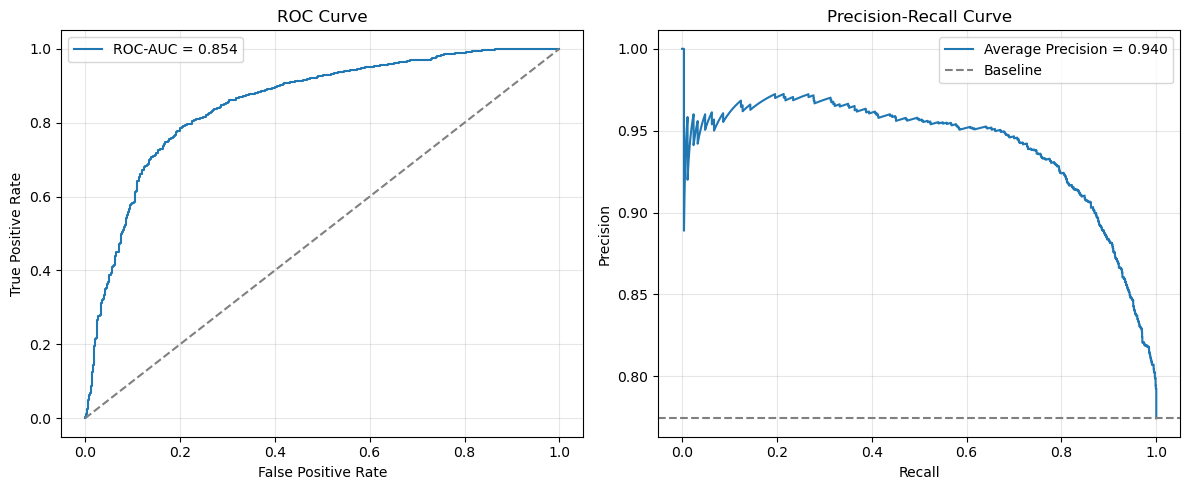

ROC-AUC = 0.854
Average Precision = 0.940


In [19]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    auc,
    average_precision_score,
    roc_auc_score
)

# Ground truth
y_true = np.where(labels == 2, 1, labels)

# Continuous reconstruction error as anomaly score
y_score = -all_diff

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_true, y_score)
roc_auc = auc(fpr, tpr)

# PR curve
precision, recall, pr_thresholds = precision_recall_curve(
    y_true, y_score
)
ap = average_precision_score(y_true, y_score)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC
axes[0].plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve")
axes[0].legend()
axes[0].grid(alpha=0.3)

# PR
axes[1].plot(recall, precision, label=f"Average Precision = {ap:.3f}")
axes[1].axhline(
    y_true.mean(),
    linestyle="--",
    color="gray",
    label="Baseline"
)
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"ROC-AUC = {roc_auc:.3f}")
print(f"Average Precision = {ap:.3f}")

# GEL

In [20]:
from pathlib import Path
import numpy as np
import shutil

# Load the approach curves
approach_path = Path.cwd() / "gel_dataset" / "approach"
approach_files = sorted(approach_path.glob("*.npy"), key=lambda f: int(f.stem))
approach_curves = [np.load(f) for f in approach_files]

# Load the retraction curves
retract_path = Path.cwd() / "gel_dataset" / "retraction"
retract_files = sorted(retract_path.glob("*.npy"), key=lambda f: int(f.stem))
retract_curves = [np.load(f) for f in retract_files]

# Load the labels
labels = np.load(Path.cwd() / "gel_dataset" / "label.npy")

# Load the contact points
contactpoints = np.load(Path.cwd() / "gel_dataset" / "contact_point.npy")

young_modulus = np.load(Path.cwd() / "gel_dataset" / "young_modulus.npy")


def label_separate(labels: np.ndarray[int], 
                   label: int, 
                   *arrays: np.ndarray,
) -> tuple[list, ...]:
    """Separates data based on a specified label.

    This utility function filters multiple aligned NumPy arrays according
    to a given label. It returns subsets of the input arrays where the
    labels match the specified value.

    Parameters
    ----------
    labels : np.ndarray[int]
        Array of labels used for filtering.
    label : int
        Target label to select.
    *arrays : np.ndarray
        One or more NumPy arrays aligned with `labels`. All arrays must
        have the same length as `labels`.

    Returns
    -------
    tuple[list, ...]
        A tuple where each element corresponds to a filtered version of
        the input arrays, containing only elements whose label matches
        the specified value.

    Examples
    --------
    >>> labels = np.array([0, 0, 1, 1, 1])
    >>> label = 1
    >>> list1 = np.array([1, 2, 3, 4, 5])
    >>> list2 = np.array([5, 4, 3, 2, 1])
    >>> s_l1, s_l2 = label_separate(labels, label, list1, list2)
    >>> s_l1, s_l2
    ([3, 4, 5], [3, 2, 1])

    """

    idx = np.where(labels == label)[0]
    return tuple([[arr[i] for i in idx] for arr in arrays])



# Calculate the length of each curve
approach_curve_lengths = [curve.shape[0] for curve in approach_curves]
retract_curve_lengths = [curve.shape[0] for curve in retract_curves]

# Calculate the minimum length of approach curves and retraction curves
min_approach_curve_length = 1500
min_retract_curve_length = min(retract_curve_lengths)

resampled_approach_curves = []
resampled_contactpoints = []
for approach_curve, contactpoint in zip(approach_curves, contactpoints):
    # Resample each approach curve to adjust its length to the shortest one
    steps = np.round(
        np.linspace(0, approach_curve.shape[0] - 1, min_approach_curve_length)
    ).astype(int)
    resampled_approach_curve = approach_curve[steps][:, 1]
    resampled_approach_curves.append(resampled_approach_curve)

    # Determine the contact point for the resampled approach curve
    resampled_approach_position = approach_curve[steps][:, 0]
    resampled_contactpoint = (
        np.abs(resampled_approach_position - contactpoint).argmin()
    )
    resampled_contactpoints.append(resampled_contactpoint)

norm_approach_curves = []

for resampled_approach_curve in resampled_approach_curves:
    norm_approach_curves.append(
        (resampled_approach_curve - resampled_approach_curve.min())
        / (resampled_approach_curve.max() - resampled_approach_curve.min())
    )

# Normalize each contact point according to min approach length
norm_contact_points = []

for resampled_contactpoint in resampled_contactpoints:
    norm_contact_points.append(
        resampled_contactpoint / min_approach_curve_length
    )

In [21]:
# Put the model under eval mode
best_ae.eval()

# Construct the dataset
norm_approach_curves = torch.as_tensor(
    norm_approach_curves, 
    dtype=torch.float32
)

all_dataloader = dl.DataLoader(
    TensorDataset(norm_approach_curves, norm_approach_curves),
    batch_size=len(norm_approach_curves),
    shuffle=False
)

# Collect the original curves and corresponding reconstruction
with torch.no_grad():
    for indx, batch in enumerate(all_dataloader):
        x_list, y_list = batch
        y_hat_list, _, = best_ae(x_list)

# Transfer them into Numpy array
y_list = x_list.numpy()
y_hat_list = y_hat_list.numpy()

# Extract the good curves and corresponding reconstruction
(
    good_curves,
    good_reconstructions,
) = label_separate(
    labels,
    1,
    y_list,
    y_hat_list,
)

# Extract the good curves and corresponding reconstruction
(
    bad_curves,
    bad_reconstructions,
) = label_separate(
    labels,
    0,
    y_list,
    y_hat_list,
)

# Transfer them into Numpy array
(
    good_curves, 
    good_reconstructions, 
    bad_curves, 
    bad_reconstructions
) = (
    np.array(good_curves),
    np.array(good_reconstructions),
    np.array(bad_curves),
    np.array(bad_reconstructions),
)

In [22]:
all_diff = abs(y_list[:,:] - y_hat_list[:,:]).mean(axis=1)

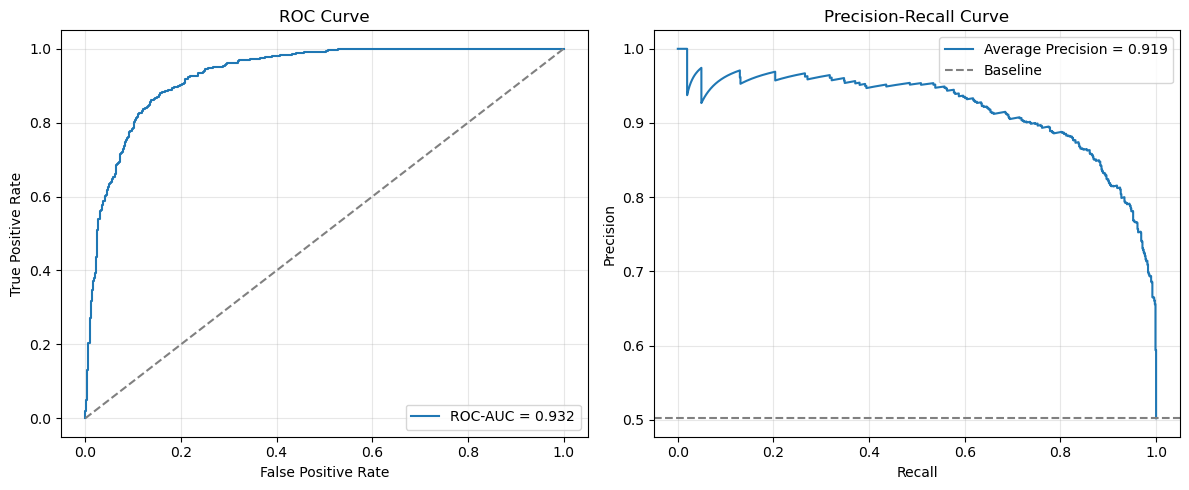

ROC-AUC = 0.932
Average Precision = 0.919


In [23]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    auc,
    average_precision_score,
    roc_auc_score
)

# Ground truth
y_true = np.where(labels == 2, 1, labels)

# Continuous reconstruction error as anomaly score
y_score = -all_diff

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_true, y_score)
roc_auc = auc(fpr, tpr)

# PR curve
precision, recall, pr_thresholds = precision_recall_curve(
    y_true, y_score
)
ap = average_precision_score(y_true, y_score)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC
axes[0].plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve")
axes[0].legend()
axes[0].grid(alpha=0.3)

# PR
axes[1].plot(recall, precision, label=f"Average Precision = {ap:.3f}")
axes[1].axhline(
    y_true.mean(),
    linestyle="--",
    color="gray",
    label="Baseline"
)
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"ROC-AUC = {roc_auc:.3f}")
print(f"Average Precision = {ap:.3f}")